# 03. EDA — разведочный анализ данных

**EDA (Exploratory Data Analysis)** — этап изучения данных **перед** построением модели. Цель — понять данные настолько, чтобы осмысленно подойти к моделированию.

**Отличие от `02_plots_practice.ipynb`:** там мы **тренировались** строить графики. Здесь — **исследуем данные** с конкретной целью: подготовиться к модели.

## Содержание

1. [Импорты и настройка](#1-импорты-и-настройка)
2. [Загрузка данных](#2-загрузка-данных)
3. [Первичный обзор](#3-первичный-обзор)
4. [Анализ целевой переменной `quality`](#4-анализ-целевой-переменной-quality)
5. [Анализ признака `type` (red vs white)](#5-анализ-признака-type-red-vs-white)
6. [Распределения числовых признаков](#6-распределения-числовых-признаков)
7. [Сравнение red vs white по ключевым признакам](#7-сравнение-red-vs-white-по-ключевым-признакам)
8. [Корреляции](#8-корреляции)
9. [Выбросы](#9-выбросы)
10. [Итоговые выводы перед моделированием](#10-итоговые-выводы-перед-моделированием)

## 1. Импорты и настройка

**Что используем:**
- `pandas` — работа с таблицами.
- `matplotlib` / `seaborn` — графики.
- `numpy` — понадобится для числовых операций (логарифмы, округления).

**Настройка темы:** `darkgrid` — для всех графиков ниже.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")

## 2. Загрузка данных

Читаем CSV в `df`. Проверяем `shape` — сколько строк и столбцов.

**Ожидаем:** (6497, 13).

In [2]:
df = pd.read_csv("../data/raw/wine_quality_merged.csv")
df.shape

(6497, 13)

## 3. Первичный обзор

Смотрим на данные «с высоты птичьего полёта». Прежде чем строить графики и модели, убедимся, что данные «в порядке».

### Расшифровка команд

**1. `df.info()`**

```python
df.info()
```

Выводит **краткую сводку** о таблице:
- сколько строк (RangeIndex);
- сколько столбцов;
- для каждого столбца: сколько непустых значений (**Non-Null Count**) и тип данных (**Dtype**);
- сколько памяти занимает таблица.

**Зачем:** за один вызов увидеть «паспорт» датасета — размер, типы, пропуски.

**2. `df.describe()`**

```python
df.describe()
```

Выводит **статистику** по каждому **числовому** столбцу:
- `count` — сколько непустых значений;
- `mean` — среднее;
- `std` — стандартное отклонение (мера разброса);
- `min`, `25%`, `50%`, `75%`, `max` — минимум, квартили, максимум.

**Зачем:** быстро понять, как «выглядят» числа. Есть ли странные значения (например, `pH = 100` или `alcohol = 500`).

**Важно:** по умолчанию `describe()` показывает **только числовые** столбцы. Текстовые (как `type`) — не попадают.

**3. `df.isna().sum()`**

```python
df.isna().sum()
```

- `df.isna()` — возвращает **такую же таблицу**, но вместо значений — `True`/`False`: `True` там, где пропуск (`NaN`).
- `.sum()` — суммирует `True` (как 1) по каждому столбцу.

**Результат:** количество пропусков в каждом столбце.

**Зачем:** пропуски нужно обрабатывать (заполнять или удалять). Если их нет — отлично, одним шагом меньше.

**4. `df.duplicated().sum()`**

```python
df.duplicated().sum()
```

- `df.duplicated()` — возвращает **серию из `True`/`False`**: `True` для строк, которые **полностью совпадают** с какой-то **предыдущей** строкой (все 13 значений равны).
- `.sum()` — сколько таких строк.

**Результат:** количество **полных дубликатов** в датасете.

**Зачем:** дубликаты искажают обучение модели — если одинаковые строки попадут в train и test, метрики будут **завышены** (data leakage).

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB


In [4]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


In [5]:
df.isna().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
type                    0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(1177)

In [7]:
# Сколько уникальных строк останется после удаления дубликатов
print("Всего строк:", len(df))
print("Уникальных строк:", len(df.drop_duplicates()))
print("Дубликатов:", len(df) - len(df.drop_duplicates()))

# Распределение quality в дубликатах и уникальных
print("\nРаспределение quality (все строки):")
print(df["quality"].value_counts().sort_index())

print("\nРаспределение quality (только уникальные):")
print(df.drop_duplicates()["quality"].value_counts().sort_index())

Всего строк: 6497
Уникальных строк: 5320
Дубликатов: 1177

Распределение quality (все строки):
quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64

Распределение quality (только уникальные):
quality
3      30
4     206
5    1752
6    2323
7     856
8     148
9       5
Name: count, dtype: int64


### Что мы увидели

**`df.info()`:**
- **6497 строк**, **13 столбцов**.
- **Пропусков нет** — Non-Null Count = 6497 у всех столбцов.
- Типы: 11 столбцов `float64` (химические признаки), `quality` — `int64`, `type` — `str`.
- Память: 660 КБ (датасет маленький).

**`df.describe()`:**
- **Разные масштабы**: `density` ~0.99–1.04, `pH` ~3, `alcohol` ~8–15, а `total sulfur dioxide` до **440**.
- **`residual sugar`** — max **65.8**, хотя 75% вин ≤ 8.1 (сильный «хвост»).
- **`quality`**: min = 3, max = 9, среднее = 5.82.

**`df.isna().sum()`:**
- **0 пропусков** во всех 13 столбцах. Данные чистые.

**`df.duplicated().sum()`:**
- **1177 полных дубликатов** — ~18% датасета.
- Это **много**. Решение — **удалить** (см. следующий раздел).

### Выводы по первичному обзору

- Датасет **чистый** (нет пропусков), но содержит **много дубликатов**.
- Признаки имеют **очень разные масштабы** — для KNN понадобится **масштабирование**.
- `residual sugar` и `total sulfur dioxide` имеют **сильные хвосты** — возможны выбросы.
- Целевая переменная `quality` имеет **дисбаланс классов** (разберём в разделе 4).

### Дубликаты — решение: удаляем

`df.duplicated().sum()` показал **1177 полных дубликатов** — это ~18% датасета.

**Что такое полный дубликат:** две (или больше) строки, у которых **все 13 значений совпадают**.

**Почему это проблема:**
- Если дубликат попадёт в train и test → модель его «запомнит» → метрики будут завышены (**data leakage**).
- 1177 из 6497 — это существенно.

**Проверили распределение `quality`:**

| Оценка | Все строки | Уникальные | Удалено |
|--------|------------|------------|---------|
| 3      | 30         | 30         | 0       |
| 4      | 216        | 206        | 10      |
| 5      | 2138       | 1752       | 386     |
| 6      | 2836       | 2323       | 513     |
| 7      | 1079       | 856        | 223     |
| 8      | 193        | 148        | 45      |
| 9      | 5          | 5          | 0       |

**Что видим:**
- Дубликаты «размазаны» по всем классам, кроме 3 и 9 — не технический сбой, а реальные повторы.
- Пропорции классов сохранились.

**Решение: удаляем полные дубликаты.**

### Расшифровка команды `drop_duplicates()`

```python
df = df.drop_duplicates()
df.shape
```

- **`df.drop_duplicates()`** — возвращает **новый** DataFrame **без полных дубликатов**.
  - По умолчанию проверяет **все столбцы**: строка считается дубликатом, если **все 13 значений** совпадают с другой строкой.

- **`df = ...`** — **присваиваем результат обратно в `df`**. Без этого `df` остался бы старым.

- **`df.shape`** — проверяем размер: должно быть **(5320, 13)**.

**Важно:** с этого момента все дальнейшие шаги работают с `df` в **5320 строк**.

In [8]:
df = df.drop_duplicates()
df.shape

(5320, 13)

## 4. Анализ целевой переменной `quality`

**`quality` — целевая переменная.** Это то, что модель будет предсказывать.

**Что важно понять:**
- Какие оценки встречаются (от 3 до 9).
- **Сбалансированы ли классы** — сколько вин на каждую оценку.
- Есть ли **дисбаланс** — если одна оценка сильно преобладает, модель будет «лениться» предсказывать редкие.

### Расшифровка команд

**1. `df["quality"].value_counts().sort_index()`**

```python
df["quality"].value_counts().sort_index()
```

Это **цепочка методов** (мы уже разбирали её в ноутбуке 02):
- `df["quality"]` — достаём столбец `quality`.
- `.value_counts()` — считаем, сколько раз встречается каждая оценка.
- `.sort_index()` — сортируем по возрастанию оценки (3, 4, 5, 6...).

**Результат:** таблица «оценка → количество».

**2. `df["quality"].value_counts(normalize=True).sort_index() * 100`**

```python
df["quality"].value_counts(normalize=True).sort_index() * 100
```

- **`normalize=True`** — вместо **количества** выводит **доли** (от 0 до 1).
- **`* 100`** — превращает доли в **проценты**.

**Результат:** «оценка → процент от общего числа».

**Зачем:** удобнее оценивать дисбаланс в процентах. «Оценка 6 = 43%» понятнее, чем «оценка 6 = 2323 штуки».

**3. `sns.countplot(data=df, x="quality")` + `plt.title(...)` + `plt.show()`**

```python
sns.countplot(data=df, x="quality")
plt.title("Распределение оценок quality (без дубликатов)")
plt.show()
```

- **`sns.countplot(...)`** — рисует **столбчатую диаграмму частот** (мы её разбирали в ноутбуке 02).
- **`plt.title("...")`** — добавляет **заголовок** к графику.
- **`plt.show()`** — команда matplotlib «отобразить график».

In [9]:
df["quality"].value_counts().sort_index()

quality
3      30
4     206
5    1752
6    2323
7     856
8     148
9       5
Name: count, dtype: int64

In [10]:
df["quality"].value_counts(normalize=True).sort_index() * 100

quality
3     0.563910
4     3.872180
5    32.932331
6    43.665414
7    16.090226
8     2.781955
9     0.093985
Name: proportion, dtype: float64

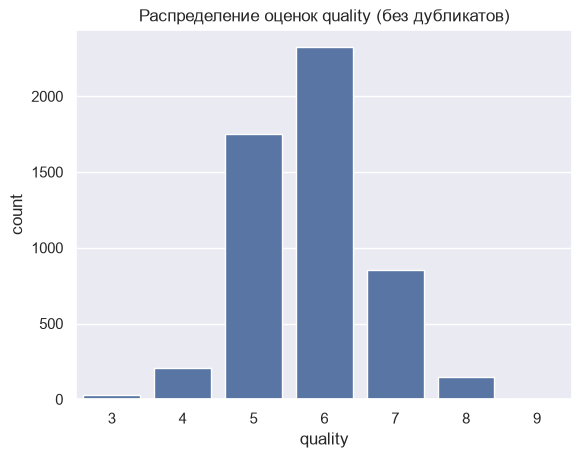

In [11]:
sns.countplot(data=df, x="quality")
plt.title("Распределение оценок quality (без дубликатов)")
plt.show()

### Что мы видим на нашем графике

**Точные числа (после удаления дубликатов, 5320 строк):**

| Оценка | Количество | Процент |
|--------|------------|---------|
| 3      | 30         | 0.56%   |
| 4      | 206        | 3.87%   |
| 5      | 1752       | 32.93%  |
| 6      | 2323       | 43.67%  |
| 7      | 856        | 16.09%  |
| 8      | 148        | 2.78%   |
| 9      | 5          | 0.09%   |

### Главное: сильный дисбаланс классов

- **Оценки 5 и 6 вместе** — это **76.6%** всех вин (4057 из 5320).
- **Оценка 6 — самая частая**, почти половина датасета (43.67%).
- **Оценка 5 — вторая**, треть датасета (32.93%).
- **Оценки 3 и 9 — почти отсутствуют** (0.56% и 0.09%).
- **Оценки 4 и 8 — редкие**, меньше 4% каждая.

### Что это значит для модели

Если модель **всегда** предсказывает 6, она угадает **43.67%** случаев — просто по «популярности» класса. Если «6 или 5» — уже **76.6%**. Это **обманчиво высокая точность** (accuracy), которая **скрывает неумение** предсказывать редкие оценки.

### Возможные подходы (обсудим в ноутбуке с моделями)

- **Объединить редкие классы**: например, «низкое» (3–4), «среднее» (5–6), «высокое» (7–9). Тогда задача станет сбалансированнее.
- **Использовать `class_weight="balanced"`** в модели — она автоматически компенсирует дисбаланс.
- **Выбирать правильные метрики**: не `accuracy`, а `f1-score` или `balanced_accuracy`.
- **Oversampling / undersampling** — искусственно выровнять классы.

### Сравнение с ноутбуком 02 (до удаления дубликатов)

| Оценка | Было (6497 строк) | Стало (5320) | Δ |
|--------|-------------------|--------------|---|
| 5+6    | ~77%              | 76.6%        | почти не изменилось |
| 3, 4   | ~3.8%             | 4.4%         | чуть больше |
| 7, 8   | ~19%              | 18.9%        | почти не изменилось |

**Вывод:** удаление дубликатов **не сломало** структуру распределения. Пропорции сохранились. Это хорошо — значит, мы почистили данные, не исказив их.

## 5. Анализ признака `type` (red vs white)

**`type`** — категориальный признак: `red` (красное) или `white` (белое).

**Что важно понять:**
- Сколько каких вин.
- Не доминирует ли один тип.
- В **машинном обучении** этот признак надо будет **преобразовать в числа** (модели не понимают строки).

### Расшифровка команд

**1. `df["type"].value_counts()`**

```python
df["type"].value_counts()
```

Считает, сколько раз встречается `red` и `white`.

**2. `df["type"].value_counts(normalize=True) * 100`**

```python
df["type"].value_counts(normalize=True) * 100
```

То же, но в **процентах**.

**3. `sns.countplot(data=df, x="type")`**

```python
sns.countplot(data=df, x="type")
plt.title("Распределение типа вина (red vs white)")
plt.show()
```

Столбчатая диаграмма частот по `type`.

### Расшифровка команды `groupby`

```python
df.groupby("type")["quality"].describe()
```

Это **цепочка методов**:

- **`df.groupby("type")`** — **группирует** строки по значению столбца `type`. Получаются две группы: все `red` и все `white`.
- **`["quality"]`** — из каждой группы берём **только столбец `quality`**.
- **`.describe()`** — статистика (count, mean, std, квартили, min, max) **отдельно для каждой группы**.

**Результат:** таблица, где строки — группы (`red`, `white`), а столбцы — статистики.

**Зачем:** сравнить `quality` между типами. Если средние сильно различаются — `type` важен.

In [12]:
df["type"].value_counts()

type
white    3961
red      1359
Name: count, dtype: int64

In [13]:
df["type"].value_counts(normalize=True) * 100

type
white    74.454887
red      25.545113
Name: proportion, dtype: float64

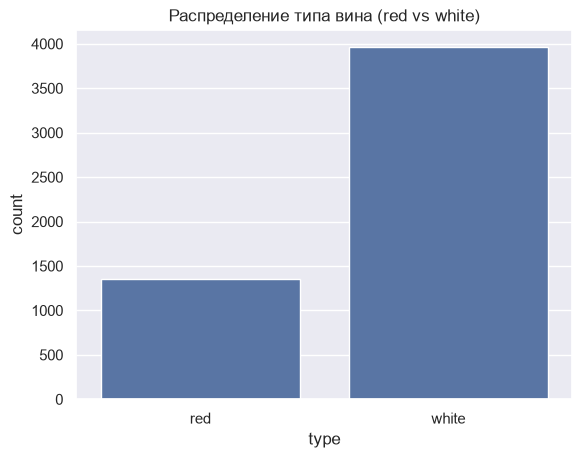

In [14]:
sns.countplot(data=df, x="type")
plt.title("Распределение типа вина (red vs white)")
plt.show()

In [15]:
df.groupby("type")["quality"].describe()

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
red,1359.0,5.623252,0.823578,3.0,5.0,6.0,6.0,8.0
white,3961.0,5.854835,0.890683,3.0,5.0,6.0,6.0,9.0


### Что мы видим: `quality` по типам вина

**Статистика `quality` отдельно для red и white:**

| Тип   | count | mean  | std  | min | 25% | 50% | 75% | max |
|-------|-------|-------|------|-----|-----|-----|-----|-----|
| red   | 1359  | 5.62  | 0.82 | 3.0 | 5.0 | 6.0 | 6.0 | 8.0 |
| white | 3961  | 5.85  | 0.89 | 3.0 | 5.0 | 6.0 | 6.0 | 9.0 |

**Что видим:**

- **Средние близки**, но не одинаковы: red = 5.62, white = 5.85. Разница ~0.23 балла.
- **Медианы одинаковые** (6.0), квартили тоже — основная масса оценок у обоих типов одна.
- **Хвосты разные**: у white есть оценки 9, у red — максимум 8. Разброс (`std`) чуть выше у white.
- **Основная масса** и там, и там — оценки 5–6.

**Вывод: `type` влияет на `quality` слабо.**

- Разница в среднем — 0.23 балла. Не критично, но не ноль.
- Если убрать `type` из признаков — модель не сильно потеряет, но может чуть-чуть.
- **Дисбаланс `type` (74% white / 26% red) не критичен**, потому что модель предсказывает `quality`, а не `type`.

**Решение:** оставляем `type` в признаках. При обучении модели будем **отдельно проверять метрики для red и white** — чтобы убедиться, что модель одинаково хорошо работает на обоих типах.


## 6. Распределения числовых признаков

**11 числовых признаков** — химические показатели вина. Смотрим, как каждый распределён.

**Что важно понять:**
- Форма (симметричная, скошенная, с несколькими пиками).
- Масштабы (одно дело — `pH` около 3, другое — `total sulfur dioxide` до 440).
- Есть ли признаки с длинными «хвостами» (то есть с выбросами).

### Расшифровка команды

```python
df.hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()
```

- **`df.hist(...)`** — **метод pandas**, который рисует гистограммы для **всех числовых столбцов** сразу, в одной сетке. Не надо вызывать `sns.histplot` 11 раз.
  - **`figsize=(14, 10)`** — размер всего «полотна» с графиками (ширина, высота в дюймах).
  - **`bins=30`** — 30 столбиков на каждой гистограмме.

- **`plt.tight_layout()`** — автоматически **подгоняет отступы** между графиками, чтобы подписи осей не перекрывались.

- **`plt.show()`** — показать.

**Зачем:** понять, какие признаки нужно будет **масштабировать** перед моделью. Для KNN это критично — без масштабирования признаки с большими числами будут «перекрикивать» остальные.

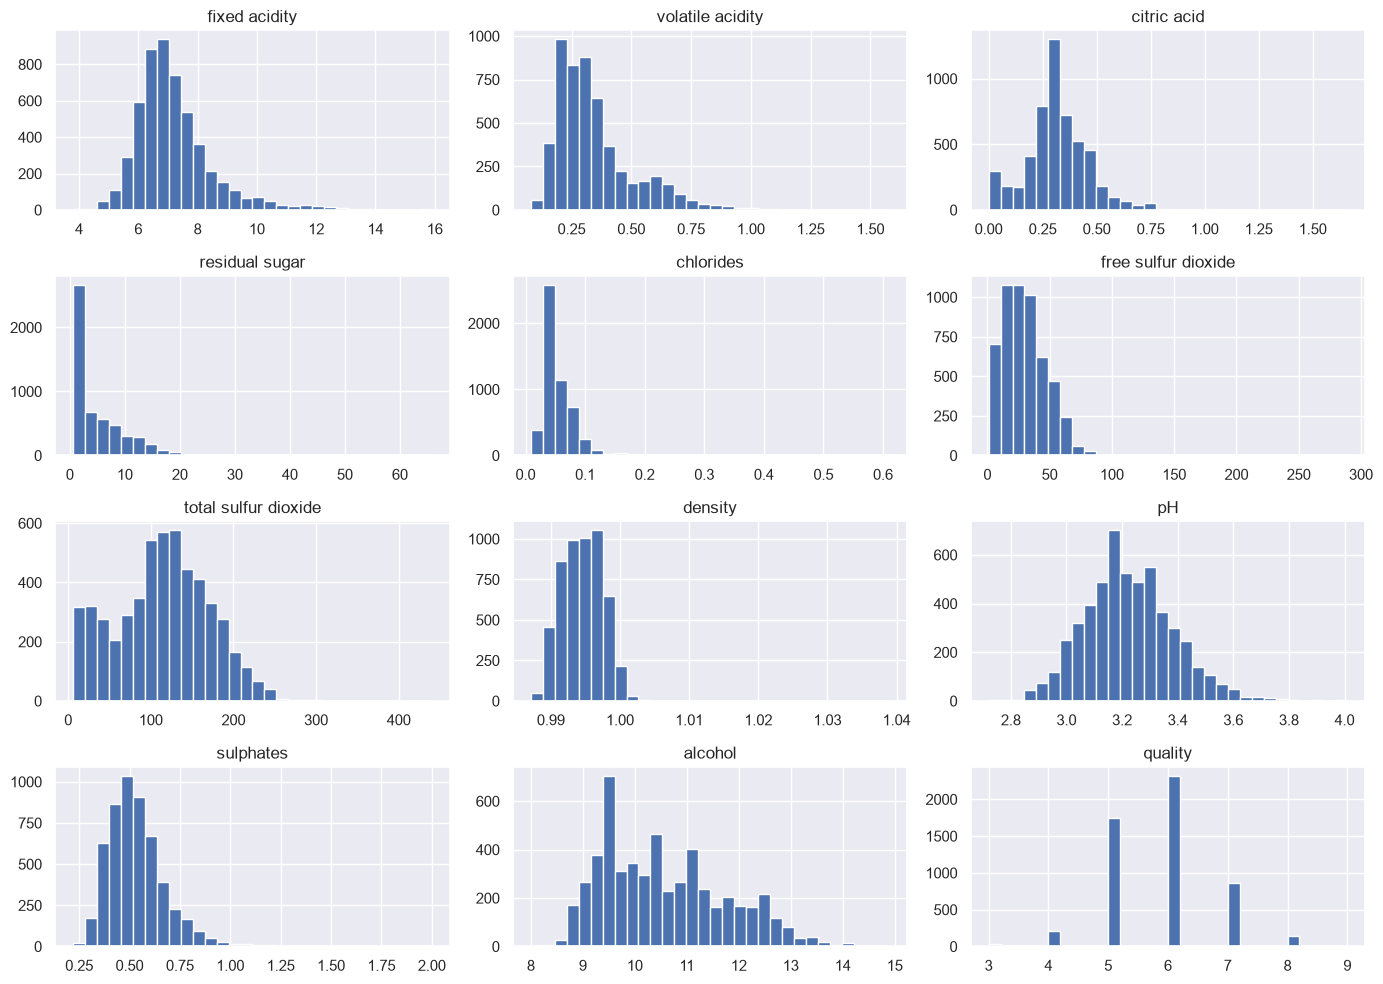

In [16]:
df.hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()

### Что мы видим: распределения числовых признаков

**Три группы признаков по форме распределения:**

#### 🟢 Близкие к «колоколу» (нормальное распределение)
- `fixed acidity` — пик ~7.
- `density` — почти симметрично, пик ~0.996.
- `pH` — классический «колокол», центр ~3.2.
- `alcohol` — пик ~9–10, хвост вправо.
- `sulphates` — пик ~0.5, хвост вправо.

#### 🟡 Скошенные вправо (хвост к большим значениям)
- `volatile acidity` — пик у 0.25–0.4, хвост до 1.5.
- `citric acid` — много нулей, хвост вправо.
- `chlorides` — пик ~0.05, хвост до 0.6.

#### 🔴 Сильно скошенные (очень длинный хвост)
- **`residual sugar`** — пик у 1–5, но максимум **65**. Огромный хвост.
- **`total sulfur dioxide`** — горб около 100, хвост до **440**.
- **`free sulfur dioxide`** — пик у 20–30, хвост до **290**.

### Главный вывод: нужны разные масштабы

**Диапазоны признаков различаются в 1000 раз:**
- `density`: 0.99–1.04
- `chlorides`: 0.01–0.6
- `pH`: 2.7–4.0
- `alcohol`: 8–15
- `total sulfur dioxide`: 6–440

**Что это значит для модели:**

1. **KNN и линейные модели требуют масштабирования.** Иначе признак `total sulfur dioxide` (со значениями до 440) будет «перекрикивать» `density` (0.99–1.04), хотя `density` может быть важнее.

2. **Сильно скошенные признаки** (`residual sugar`, `total sulfur dioxide`, `free sulfur dioxide`) можно **логарифмировать** — это сожмёт хвост и сделает распределение ближе к нормальному.

3. **Деревья решений (Decision Tree, Random Forest) не требуют масштабирования** — они работают с порогами, а не с расстояниями. Но для KNN масштабирование **обязательно**.

**Что будем делать:** в ноутбуке с моделями применим `StandardScaler` (или `MinMaxScaler`) ко всем числовым признакам **перед** обучением KNN.

## 7. Сравнение red vs white по ключевым признакам

Красное и белое вино — **разные продукты**. У них могут отличаться химические показатели.

**Что важно понять:** по каким признакам red и white **сильно отличаются**.

### Расшифровка команды

```python
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

sns.boxplot(data=df, x="type", y="alcohol", ax=axes[0, 0])
sns.boxplot(data=df, x="type", y="volatile acidity", ax=axes[0, 1])
sns.boxplot(data=df, x="type", y="residual sugar", ax=axes[1, 0])
sns.boxplot(data=df, x="type", y="total sulfur dioxide", ax=axes[1, 1])

plt.tight_layout()
plt.show()
```

**Разбор:**

- **`plt.subplots(2, 2, figsize=(14, 8))`** — создаёт **сетку графиков 2×2**.
  - **`2, 2`** — 2 строки и 2 столбца (4 «ячейки» для графиков).
  - **`figsize=(14, 8)`** — размер всего полотна.
  - **Возвращает два объекта:** `fig` (всё полотно) и `axes` (массив из 4 «ячеек»).
  - **`axes`** — это двумерный массив: `axes[0, 0]`, `axes[0, 1]`, `axes[1, 0]`, `axes[1, 1]`.

- **`ax=axes[0, 0]`** — «рисуй этот график **в ячейке `[0, 0]`**» (левая верхняя).
  - `axes[0, 1]` — правая верхняя.
  - `axes[1, 0]` — левая нижняя.
  - `axes[1, 1]` — правая нижняя.

- **Внутри каждого `sns.boxplot(...)`** — параметр `ax=` указывает, **куда** рисовать. Без этого все 4 графика наложились бы друг на друга.

- **`x="type"`** — по оси X категории `red` / `white`.
- **`y="признак"`** — по оси Y числовой признак.

**Зачем `plt.subplots`:** когда графиков несколько, удобно расположить их **сеткой** — сравнивать легче.

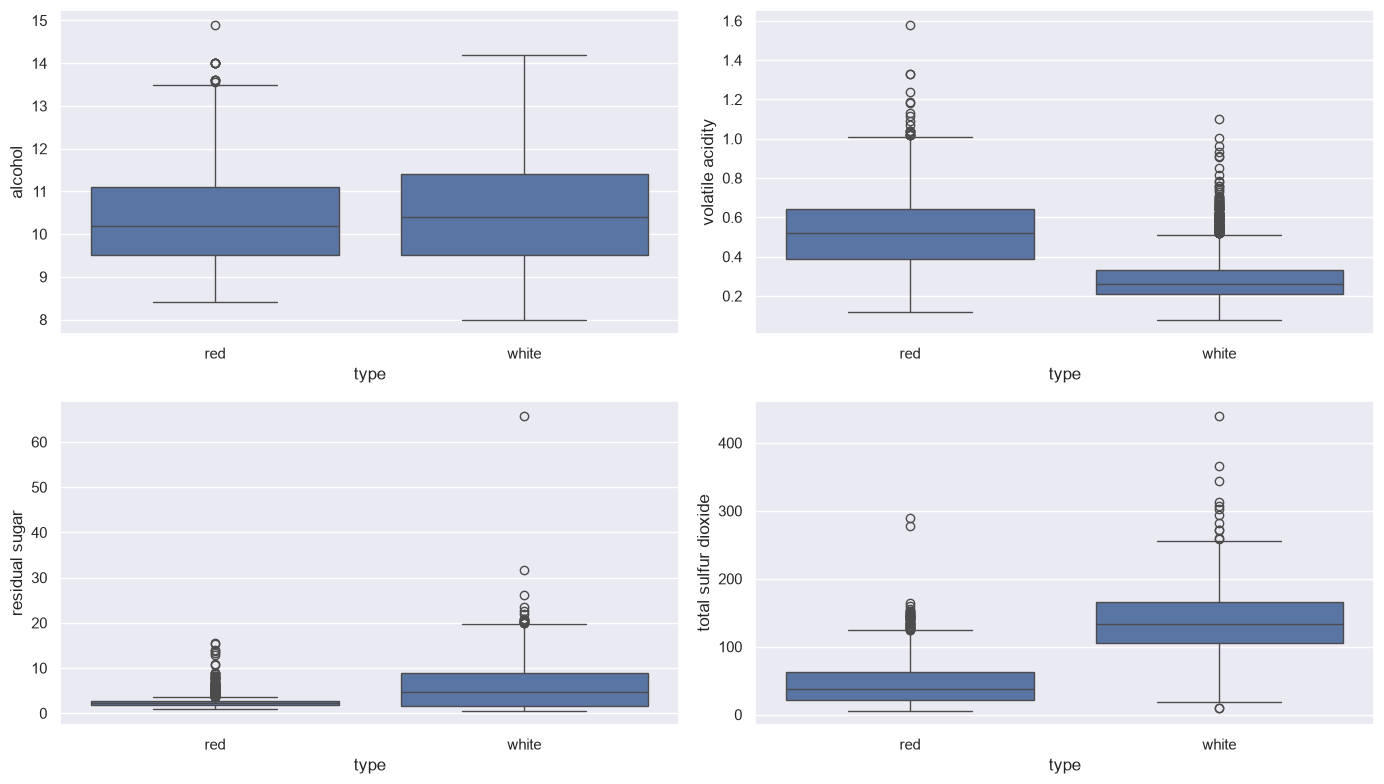

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

sns.boxplot(data=df, x="type", y="alcohol", ax=axes[0, 0])
sns.boxplot(data=df, x="type", y="volatile acidity", ax=axes[0, 1])
sns.boxplot(data=df, x="type", y="residual sugar", ax=axes[1, 0])
sns.boxplot(data=df, x="type", y="total sulfur dioxide", ax=axes[1, 1])

plt.tight_layout()
plt.show()

### Что мы видим: red vs white по ключевым признакам

**1. `alcohol`** — почти одинаково.
- red: медиана ~10, ящик 9.5–11.
- white: медиана ~10.5, ящик 9.5–11.5.
- Небольшой сдвиг вправо у white, но основная масса пересекается.

**2. `volatile acidity`** — **сильное отличие**.
- red: медиана ~0.5, ящик 0.4–0.65.
- white: медиана ~0.25, ящик 0.2–0.35.
- **У red в 2 раза выше**, чем у white. Самый «разделяющий» признак.

**3. `residual sugar`** — **сильное отличие**.
- red: медиана ~2, ящик 1.5–3. Максимум ~15.
- white: медиана ~5, ящик 3–8. Хвост до **65**.
- **У white в 2–3 раза выше** — белое вино слаще.

**4. `total sulfur dioxide`** — **сильное отличие**.
- red: медиана ~25, ящик 15–50. Максимум ~150.
- white: медиана ~130, ящик 100–170. Хвост до **440**.
- **У white в 5 раз выше** — технологическая особенность белого вина.

### Главный вывод

**`type` — сильный признак.** Он «связан» с тремя другими признаками:
- `volatile acidity` (у red выше),
- `residual sugar` (у white выше),
- `total sulfur dioxide` (у white выше).

**Что это значит для модели:**
- `type` **несёт информацию** о многих других признаках — полезен как признак.
- **Удалять `type` не будем.** Наоборот, он может помочь модели.
- Но надо помнить: если `type` очень сильно коррелирует с другими признаками, у линейных моделей может возникнуть **мультиколлинеарность**. У KNN и деревьев такой проблемы нет.

**Что дальше:** посмотрим корреляции между **всеми** числовыми признаками через heatmap.

## 8. Корреляции

**Корреляция** — число от −1 до 1, показывающее **связь между двумя признаками**.

- **+1** — сильная **прямая** связь (больше одно → больше другое).
- **−1** — сильная **обратная** связь (больше одно → меньше другое).
- **0** — связи нет.

**Что важно понять:**
- Какие признаки **связаны с `quality`** → потенциально важные признаки для модели.
- Какие признаки **связаны друг с другом** → **мультиколлинеарность**. Для линейных моделей — плохо, для KNN и деревьев — не критично.

**Важно:** `type` — текст, в корреляции **не попадёт**. Его надо будет **преобразовать в числа** (0/1) отдельно, если хотим посчитать. Пока считаем только по числовым столбцам.

### Расшифровка команды

```python
plt.figure(figsize=(12, 9))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)
plt.title("Корреляции между числовыми признаками")
plt.show()
```

**Построчно:**

- **`plt.figure(figsize=(12, 9))`** — создаём «полотно» для графика размером 12×9 дюймов. Нужно, чтобы уместились 12×12 подписей осей.

- **`df.corr(numeric_only=True)`** — считаем таблицу корреляций.
  - `df.corr()` — метод pandas, который считает **попарные корреляции** между всеми столбцами.
  - `numeric_only=True` — **важно**: считаем только по числовым столбцам. Без этого pandas попытается посчитать и `type` (текст) → ошибка.
  - Результат — **квадратная таблица** N×N, где N — число числовых столбцов.

- **`sns.heatmap(...)`** — рисуем **тепловую карту** из таблицы.
  - **`annot=True`** — написать **числа** в каждой клетке. Без этого будут только цвета.
  - **`fmt=".2f"`** — формат чисел: 2 знака после запятой.
  - **`cmap="coolwarm"`** — цветовая схема: **синий** (отрицательная) → **белый** (ноль) → **красный** (положительная).
  - **`center=0`** — ноль на **середине** цветовой шкалы.
  - **`square=True`** — клетки **квадратные**.

- **`plt.title("...")`** — заголовок.

- **`plt.show()`** — отобразить.

### Как читать heatmap

- **По диагонали** — всегда `1.00` (корреляция признака с самим собой).
- **Матрица симметрична** — значение для пары (A, B) = значение для (B, A). Можно смотреть только половину.
- **Ищи `quality`** — это **последняя строка и столбец**. Смотрим, где краснее/синее всего.
- **Ищи пары с корреляцией >0.7** — это сильно связанные признаки.

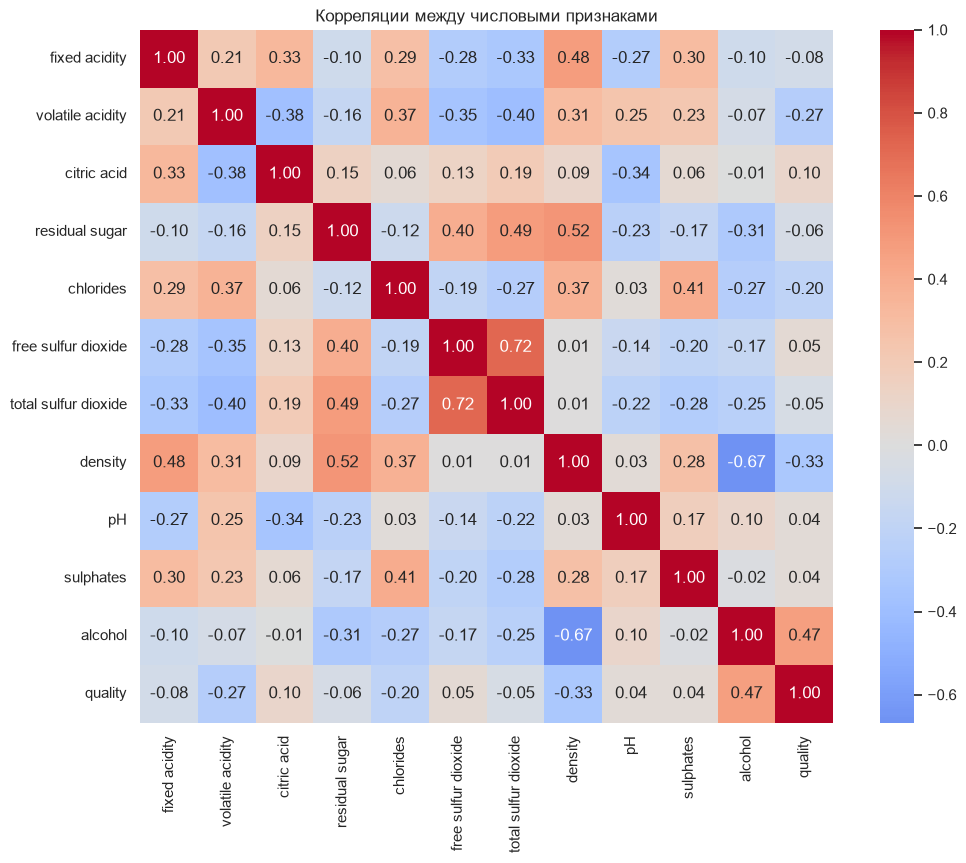

In [19]:
plt.figure(figsize=(12, 9))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)
plt.title("Корреляции между числовыми признаками")
plt.show()

### Что мы увидели

#### Связь с `quality` (последняя строка/столбец)

| Признак | Корреляция с `quality` |
|---|---|
| **`alcohol`** | **+0.47** (самая сильная положительная) |
| **`density`** | **−0.33** |
| **`volatile acidity`** | **−0.27** |
| `chlorides` | −0.20 |
| `citric acid` | +0.10 |
| `fixed acidity` | −0.08 |
| `residual sugar` | −0.06 |
| `free sulfur dioxide` | +0.05 |
| `total sulfur dioxide` | −0.05 |
| `pH` | +0.04 |
| `sulphates` | +0.04 |

**Главный вывод:** **`alcohol` — самый важный признак** для предсказания `quality`.
- **Больше алкоголя → выше оценка** (корреляция +0.47).
- **Больше `volatile acidity` → ниже оценка** (−0.27).
- **Больше `density` → ниже оценка** (−0.33).

#### Сильные связи между признаками

| Пара | Корреляция | Что значит |
|---|---|---|
| `free sulfur dioxide` ↔ `total sulfur dioxide` | **+0.72** | Дублируют друг друга |
| `density` ↔ `alcohol` | **−0.67** | Обратная связь (алкоголь легче воды) |
| `density` ↔ `residual sugar` | +0.52 | Плотность растёт с сахаром |
| `density` ↔ `fixed acidity` | +0.48 | Плотность растёт с кислотностью |
| `residual sugar` ↔ `total sulfur dioxide` | +0.49 | Технологическая связь |

#### Что это значит для модели

1. **`alcohol` — ключевой признак.** Скорее всего, будет самым важным для модели.

2. **`free sulfur dioxide` и `total sulfur dioxide` дублируют друг друга** (0.72).
   - Для модели можно **оставить только `total sulfur dioxide`** — он «включает» свободный.
   - Или оставить оба — для KNN и деревьев это не критично.

3. **`density` и `alcohol` частично дублируют** (−0.67).
   - Для **линейных моделей** это проблема (мультиколлинеарность).
   - Для **KNN и деревьев** — не критично.

4. **Мультиколлинеарность** — это когда признаки «дублируют» друг друга.
   - **Решение для линейных моделей:** удалить один из пары сильно связанных признаков.
   - **Для KNN и деревьев:** оставляем как есть.

**Что будем делать:** пока оставляем все признаки. Если при построении моделей увидим проблемы — вернёмся и почистим.

## 9. Выбросы

**Выбросы** — значения, которые сильно отличаются от основной массы. Мы их уже видели в boxplot'ах (`alcohol > 14`, `residual sugar > 30`).

**Что важно понять:**
- Где выбросов **много**, где мало.
- Это **реальные данные** или **ошибки**?
- Что с ними делать: **оставить**, **удалить**, **преобразовать**?

**Обычно:**
- Если выброс — **реальное редкое значение** (как очень крепкое вино) → **оставить**.
- Если выброс — **ошибка измерения** (например, `pH = 100`) → **удалить**.
- Если выбросов **много** и они **сильно искажают** распределение → можно **логарифмировать** признак.

**Как смотреть:** boxplot для каждого признака (мы уже строили в ноутбуке 02). Здесь — быстро проверим подозрительные столбцы.

### Расшифровка команды

```python
df.describe().T[["min", "25%", "50%", "75%", "max"]]
```

**Разбор по частям:**

- **`df.describe()`** — статистика по числовым столбцам (мы её уже разбирали). По умолчанию: строки — статистики, столбцы — признаки.

- **`.T`** — **транспонирование**. Меняет местами строки и столбцы. Теперь:
  - **строки** — признаки;
  - **столбцы** — статистики.
  
  Это удобнее: каждый признак — одна строка, легко читать.

- **`[["min", "25%", "50%", "75%", "max"]]`** — выбираем **только эти 5 столбцов** (двойные квадратные скобки — потому что выбираем **несколько** столбцов). Нам не нужны `count`, `mean`, `std`.

**Результат:** таблица, где по каждой строке — признак, а по столбцам — min, квартили, max.

**Зачем:** быстро найти признаки, где `max` **сильно отрывается** от `75%`. Это признак **выбросов** и **сильных хвостов**.

In [20]:
df.describe().T[["min", "25%", "50%", "75%", "max"]]

,min,25%,50%,75%,max
fixed acidity,3.80000,6.4000,7.00000,7.70000,15.90000
volatile acidity,0.08000,0.2300,0.30000,0.41000,1.58000
citric acid,0.00000,0.2400,0.31000,0.40000,1.66000
residual sugar,0.60000,1.8000,2.70000,7.50000,65.80000
chlorides,0.00900,0.0380,0.04700,0.06600,0.61100
free sulfur dioxide,1.00000,16.0000,28.00000,41.00000,289.00000
total sulfur dioxide,6.00000,74.0000,116.00000,153.25000,440.00000
density,0.98711,0.9922,0.99465,0.99677,1.03898
pH,2.72000,3.1100,3.21000,3.33000,4.01000
sulphates,0.22000,0.4300,0.51000,0.60000,2.00000


### Что мы увидели

**Признаки с сильными выбросами** (max сильно отрывается от 75%):

| Признак | 75% | max | Отношение |
|---|---|---|---|
| **`residual sugar`** | 7.5 | **65.8** | ~9× |
| **`chlorides`** | 0.066 | **0.611** | ~9× |
| **`free sulfur dioxide`** | 41 | **289** | ~7× |
| **`volatile acidity`** | 0.41 | **1.58** | ~4× |
| **`citric acid`** | 0.40 | **1.66** | ~4× |
| **`total sulfur dioxide`** | 153 | **440** | ~3× |
| **`sulphates`** | 0.60 | **2.00** | ~3× |
| **`fixed acidity`** | 7.7 | **15.9** | ~2× |
| **`alcohol`** | 11.4 | **14.9** | ~1.3× |

**Признаки без сильных выбросов:**
- `pH` (max 4.01 при 75% = 3.33)
- `density` (max 1.039 при 75% = 0.997)

### Выводы

1. **У 9 из 11 признаков есть выбросы.** Самые «хвостатые» — `residual sugar`, `chlorides`, `free sulfur dioxide`.

2. **Это не ошибки измерения, а реальные редкие значения.** 
   - `residual sugar = 65.8` — очень сладкое десертное вино.
   - `chlorides = 0.611` — сильно минерализованное.
   - Удалять их — **плохая идея**.

3. **Что будем делать:** **ничего не удаляем**. Причины:
   - KNN и деревья **устойчивы к выбросам** (в отличие от линейных моделей).
   - Выбросы занимают **<5%** датасета.
   - Они несут реальную информацию.

4. **Опционально:** если при обучении модели выяснится, что выбросы мешают, можно **логарифмировать** скошенные признаки (`residual sugar`, `chlorides`, `free sulfur dioxide`, `total sulfur dioxide`). Но пока — **не трогаем**.

## 10. Итоговые выводы перед моделированием

**Паспорт датасета:**
- **5320 строк** (после удаления 1177 дубликатов), **13 столбцов**.
- **Пропусков нет.**
- 11 числовых химических признаков + `quality` (целевой) + `type` (red/white).

### Что узнали

**1. Целевая переменная `quality`:**
- Оценки от 3 до 9.
- **Сильный дисбаланс:** 77% вин имеют оценку 5 или 6.
- Редкие классы: 3, 4, 8, 9 (меньше 10% вместе).
- **Проблема для модели:** accuracy будет обманчиво высокой (модель может «угадывать» только 5 и 6).

**2. Признак `type` (red vs white):**
- Дисбаланс: 74% white, 26% red.
- **Слабо влияет на `quality`** (разница в среднем 0.23 балла).
- **Сильно связан с другими признаками** (`volatile acidity`, `residual sugar`, `total sulfur dioxide`).
- **Оставляем** в модели, но надо помнить о дисбалансе.

**3. Распределения признаков:**
- **Разные масштабы** — от 0.01 (`chlorides`) до 440 (`total sulfur dioxide`).
- **KNN и линейные модели требуют масштабирования** — иначе признаки с большими числами «перекрикивают» остальные.
- Сильно скошенные признаки: `residual sugar`, `total sulfur dioxide`, `free sulfur dioxide`.

**4. Корреляции:**
- **`alcohol` — самый важный признак** (+0.47 с `quality`).
- `volatile acidity` (−0.27), `density` (−0.33) — тоже важны.
- **Мультиколлинеарность:** `free sulfur dioxide` ↔ `total sulfur dioxide` (0.72), `density` ↔ `alcohol` (−0.67).
- Для линейных моделей — надо чистить, для KNN и деревьев — не критично.

**5. Выбросы:**
- Есть почти у всех признаков, но **это реальные данные**, не ошибки.
- **Не удаляем.**

### Что делаем **перед** моделью

**Шаги предобработки (в следующем ноутбуке):**

1. **Разделение на признаки (X) и целевую переменную (y).**
   - `X` — все признаки, кроме `quality`.
   - `y` — `quality`.

2. **Кодирование `type`:**
   - Превратить `red`/`white` в числа (0/1) через `LabelEncoder` или `pd.get_dummies`.

3. **Разделение на train / test:**
   - Например, 80% / 20%.
   - **Важно:** `stratify=y`, чтобы сохранить пропорции классов `quality` в обеих частях.

4. **Масштабирование числовых признаков:**
   - `StandardScaler` — для KNN **обязательно**.
   - **Только на train** — потом применить тот же scaler к test.

5. **Обучение моделей:**
   - Начать с **KNN**.
   - Потом — Logistic Regression, Decision Tree, Random Forest.
   - Метрики: `accuracy`, `f1-score` (macro), `balanced_accuracy`.
   - Confusion matrix.

### Что **не** делаем

- **Не удаляем выбросы** — они реальные.
- **Не логарифмируем**  — попробуем сначала как есть.
- **Не объединяем редкие классы**  — сначала посмотрим на метрики.
- **Не удаляем** `free sulfur dioxide` или `density` — для KNN это не критично.
